#random forest

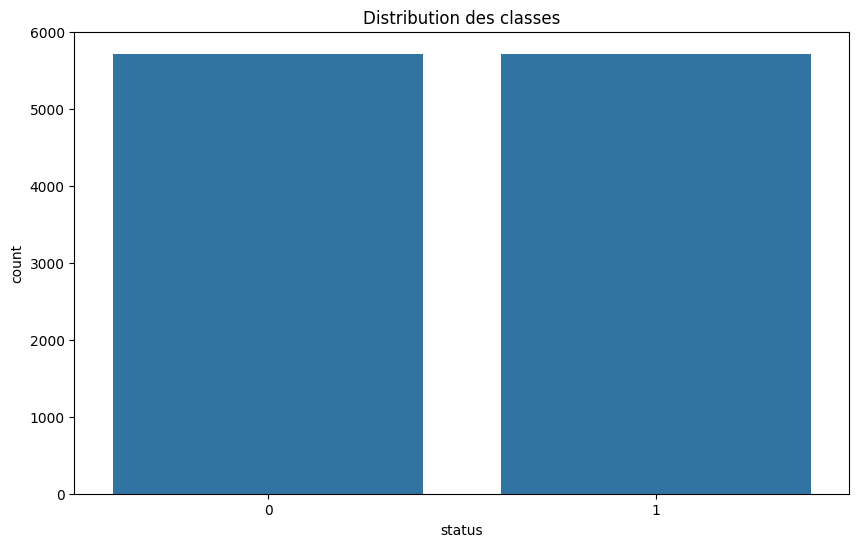

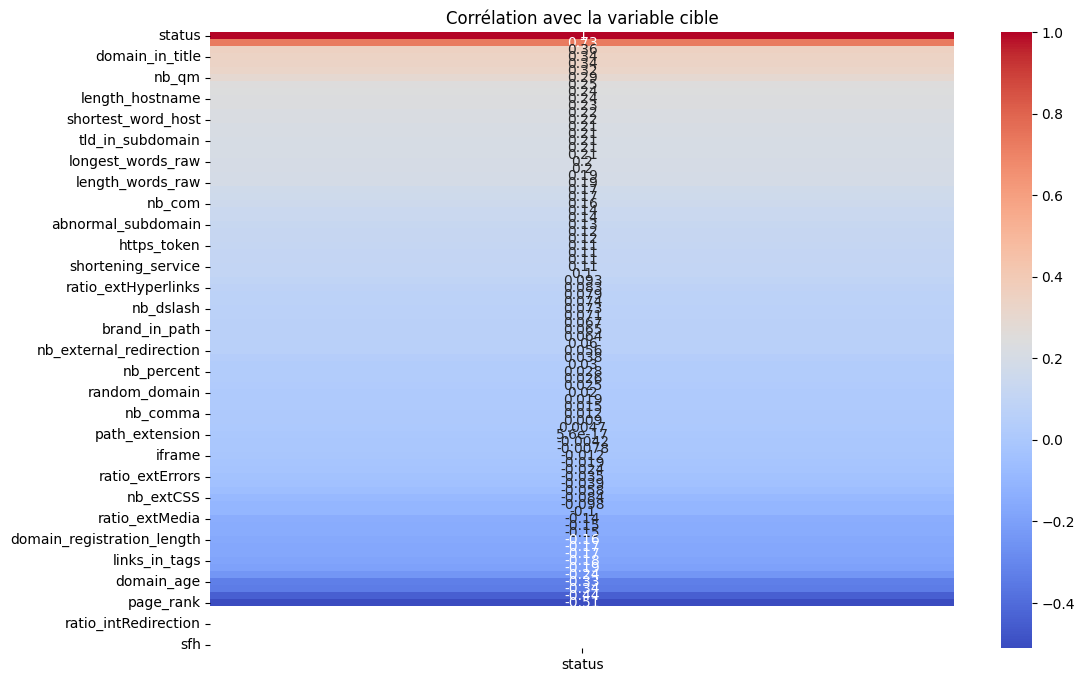

Pour une contamination de 0.005, points supprimés : 58
Pour une contamination de 0.01, points supprimés : 115
Pour une contamination de 0.02, points supprimés : 229
Distribution après SMOTE : [5709 5709]
Entraînement du RandomForest terminé.

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      1142
           1       0.97      0.96      0.97      1142

    accuracy                           0.97      2284
   macro avg       0.97      0.97      0.97      2284
weighted avg       0.97      0.97      0.97      2284



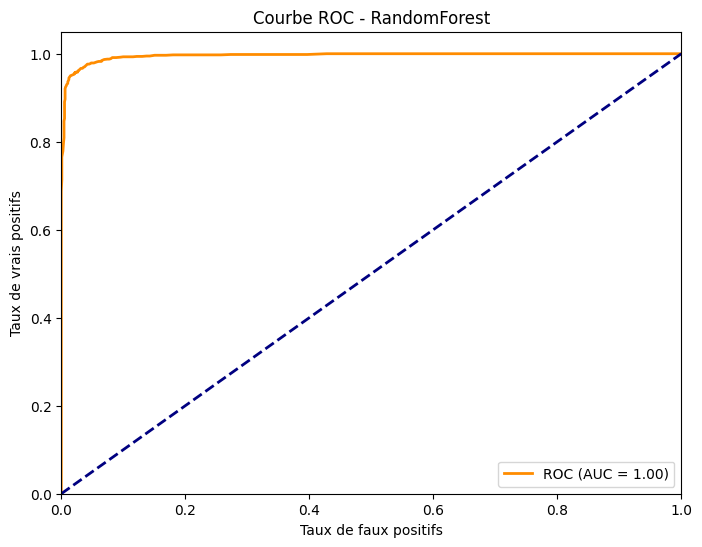

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Pour le modèle RandomForest
from sklearn.ensemble import RandomForestClassifier

# Détection d'anomalies
from sklearn.ensemble import IsolationForest

# Pour équilibrer la dataset avec SMOTE
from imblearn.over_sampling import SMOTE

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 1. Suppression des anomalies avec IsolationForest
# ---------------------------
# Test de différents niveaux de contamination
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (par exemple 1%)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
X = X[mask]
y = y[mask]

# ---------------------------
# 2. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)
print("Distribution après SMOTE :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 3. Définition et entraînement du modèle RandomForest
# ---------------------------
# On peut ajuster les hyperparamètres du RandomForest selon vos besoins
rf_model = RandomForestClassifier(n_estimators=100,    # nombre d'arbres
                                  max_depth=None,        # profondeur maximale (None = pas de limite)
                                  random_state=42,
                                  n_jobs=-1)

rf_model.fit(X_train, y_train)
print("Entraînement du RandomForest terminé.")

# ---------------------------
# 4. Évaluation du modèle
# ---------------------------
# Prédictions sur l'ensemble de test
y_pred = rf_model.predict(X_test)
print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

# Calcul de la courbe ROC
y_proba = rf_model.predict_proba(X_test)[:, 1]  # Probabilité pour la classe 1
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Affichage de la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:0.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - RandomForest')
plt.legend(loc="lower right")
plt.show()


In [ ]:
import joblib


In [ ]:
with open('random_forest_model.pkl', 'wb') as file:
    joblib.dump(rf_model, file)

#adaboost

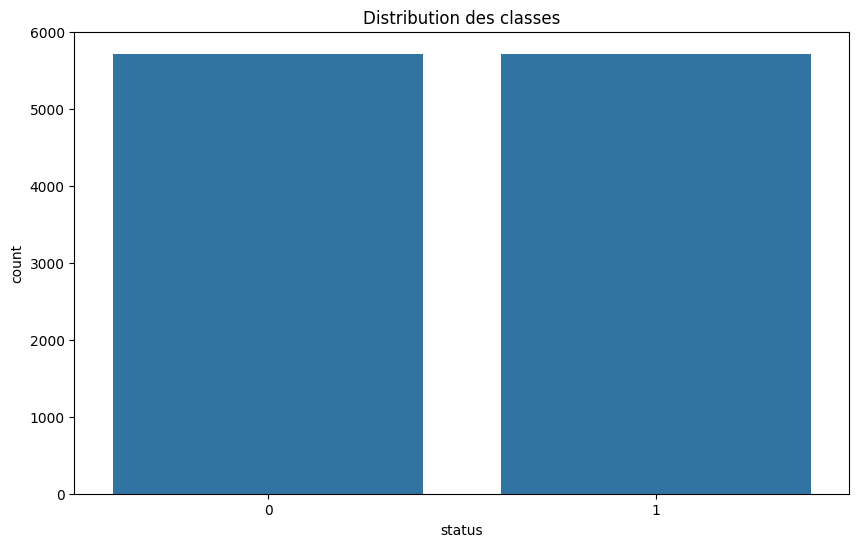

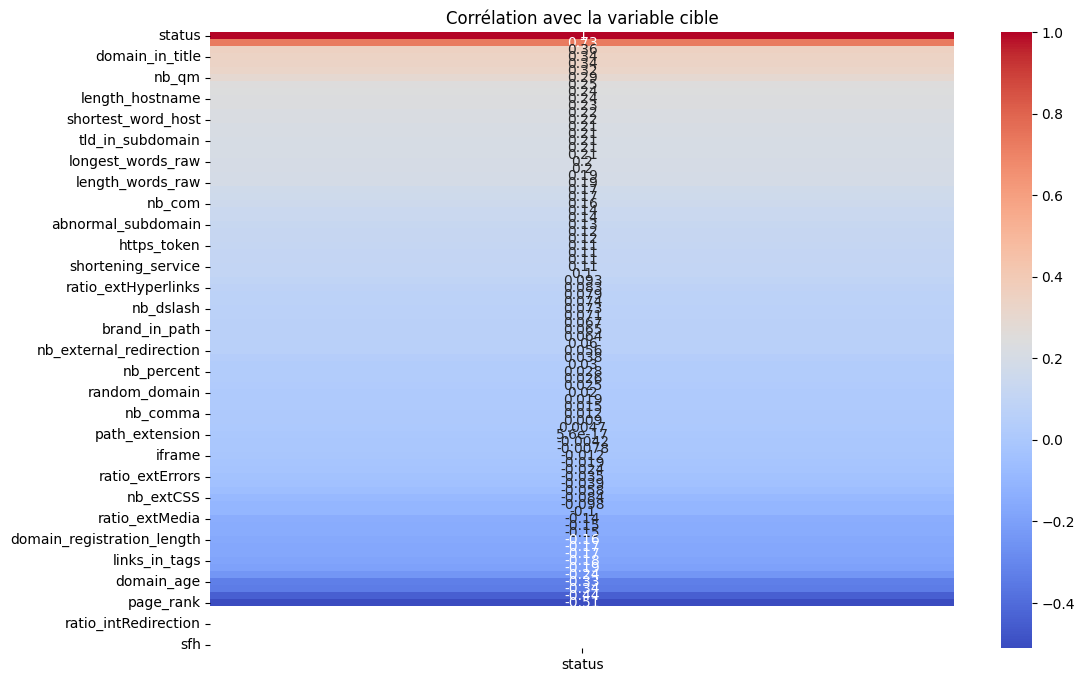

Pour une contamination de 0.005, points supprimés : 58
Pour une contamination de 0.01, points supprimés : 115
Pour une contamination de 0.02, points supprimés : 229
Distribution après SMOTE : [5709 5709]
Entraînement du modèle AdaBoost terminé.

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      1142
           1       0.95      0.94      0.95      1142

    accuracy                           0.95      2284
   macro avg       0.95      0.95      0.95      2284
weighted avg       0.95      0.95      0.95      2284



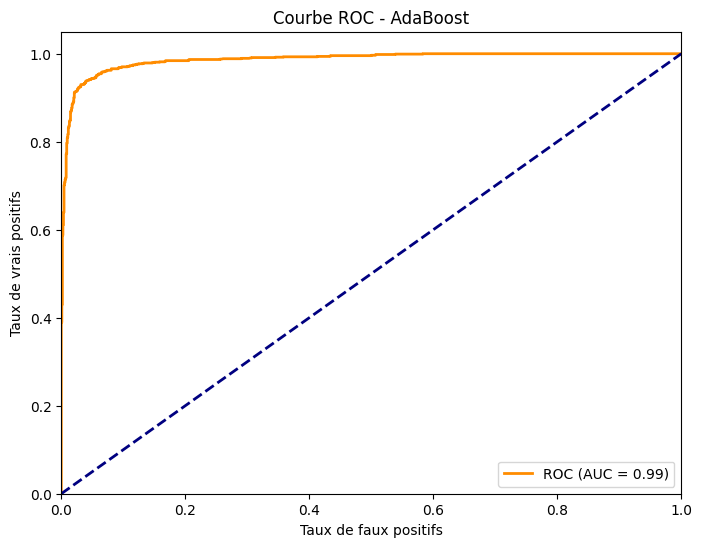

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Pour le modèle AdaBoost
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Détection d'anomalies
from sklearn.ensemble import IsolationForest

# Pour équilibrer la dataset avec SMOTE
from imblearn.over_sampling import SMOTE

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 1. Suppression des anomalies avec IsolationForest
# ---------------------------
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
X = X[mask]
y = y[mask]

# ---------------------------
# 2. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)
print("Distribution après SMOTE :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 3. Définition et entraînement du modèle AdaBoost
# ---------------------------
# Utilisation d'un DecisionTree de profondeur 1 (stump) comme estimateur de base
base_estimator = DecisionTreeClassifier(max_depth=1, random_state=42)
ada_model = AdaBoostClassifier(estimator=base_estimator,  # Notez le changement ici
                               n_estimators=100,      # nombre d'estimateurs
                               learning_rate=1.0,    # taux d'apprentissage
                               random_state=42)

ada_model.fit(X_train, y_train)
print("Entraînement du modèle AdaBoost terminé.")

# ---------------------------
# 4. Évaluation du modèle
# ---------------------------
y_pred = ada_model.predict(X_test)
print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

y_proba = ada_model.predict_proba(X_test)[:, 1]  # Probabilité pour la classe 1
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:0.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - AdaBoost')
plt.legend(loc="lower right")
plt.show()


#lightgbm

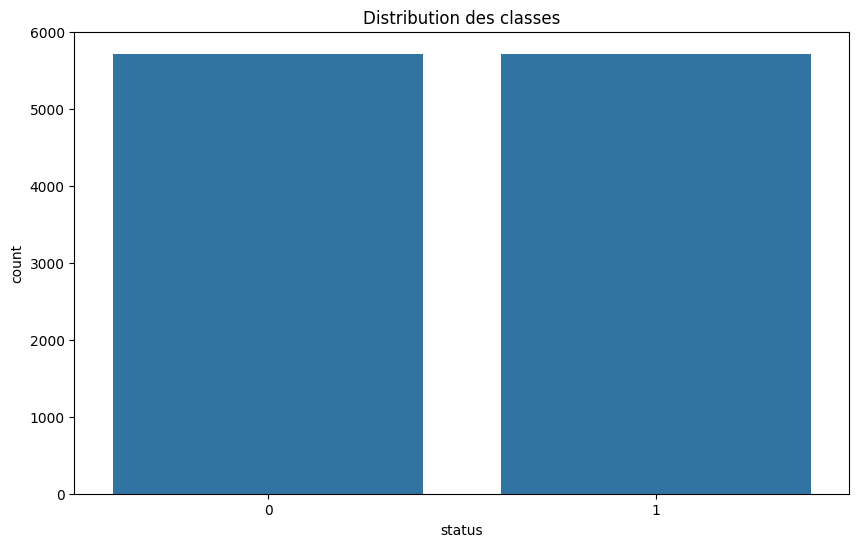

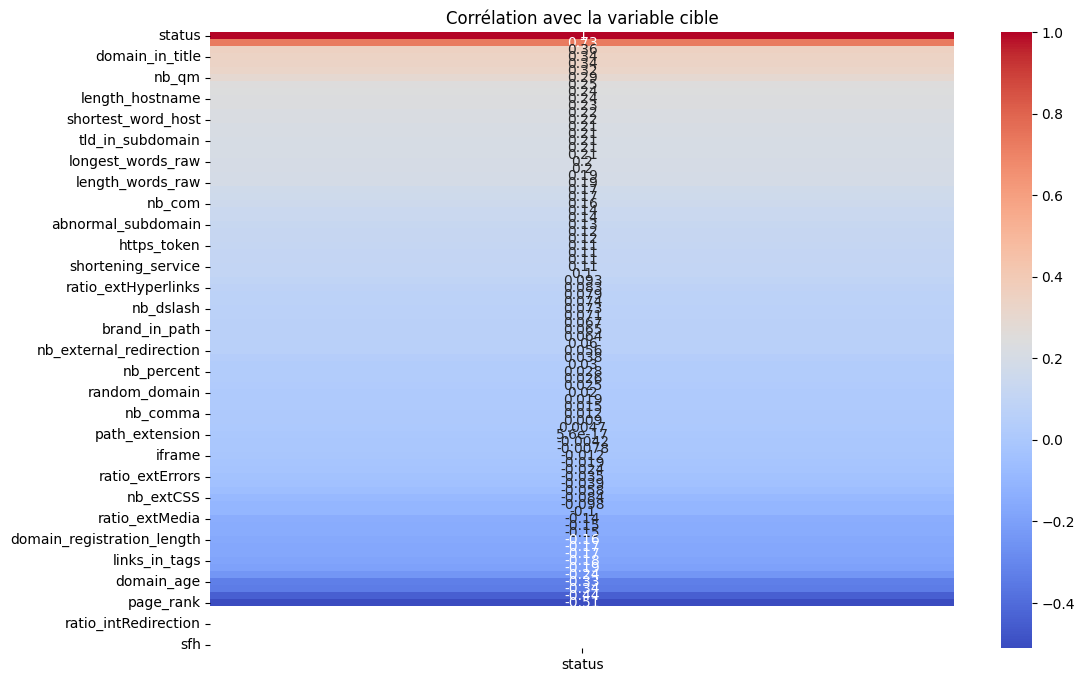

Pour une contamination de 0.005, points supprimés : 58
Pour une contamination de 0.01, points supprimés : 115
Pour une contamination de 0.02, points supprimés : 229
Distribution après SMOTE : [5709 5709]


/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:865: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  _X, _y = _LGBMCheckXY(X, y, accept_sparse=True, force_all_finite=False, ensure_min_samples=2)


[LightGBM] [Info] Number of positive: 4567, number of negative: 4567
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007512 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5141
[LightGBM] [Info] Number of data points in the train set: 9134, number of used features: 73
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Entraînement du modèle LightGBM terminé.

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1142
           1       0.97      0.96      0.97      1142

    accuracy                           0.97      2284
   macro avg       0.97      0.97      0.97      2284
weighted avg       0.97      0.97      0.97      2284



/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1007: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  X = _LGBMCheckArray(X, accept_sparse=True, force_all_finite=False)
/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1007: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  X = _LGBMCheckArray(X, accept_sparse=True, force_all_finite=False)


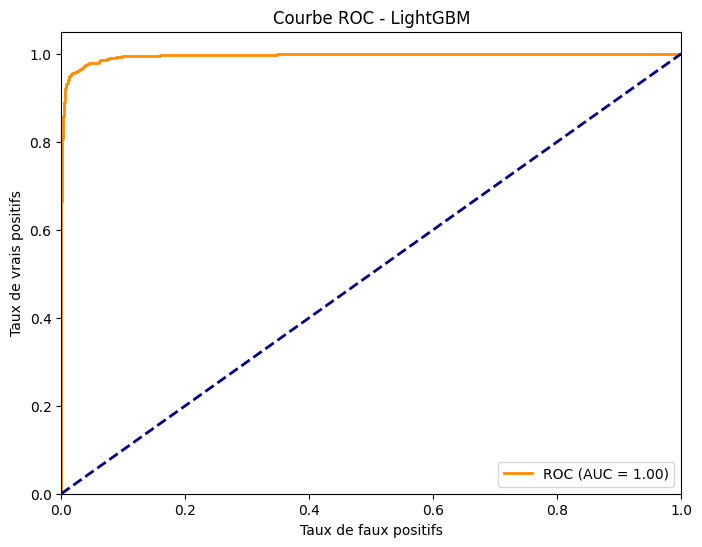

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Pour le modèle LightGBM
import lightgbm as lgb

# Détection d'anomalies
from sklearn.ensemble import IsolationForest

# Pour équilibrer la dataset avec SMOTE
from imblearn.over_sampling import SMOTE

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 1. Suppression des anomalies avec IsolationForest
# ---------------------------
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (par exemple 1%)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
X = X[mask]
y = y[mask]

# ---------------------------
# 2. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)
print("Distribution après SMOTE :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 3. Définition et entraînement du modèle LightGBM
# ---------------------------
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,    # nombre d'arbres
    learning_rate=0.1,   # taux d'apprentissage
    random_state=42
)

lgb_model.fit(X_train, y_train)
print("Entraînement du modèle LightGBM terminé.")

# ---------------------------
# 4. Évaluation du modèle
# ---------------------------
# Prédictions sur l'ensemble de test
y_pred = lgb_model.predict(X_test)
print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

# Calcul de la courbe ROC
y_proba = lgb_model.predict_proba(X_test)[:, 1]  # Probabilité pour la classe 1
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Affichage de la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:0.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - LightGBM')
plt.legend(loc="lower right")
plt.show()


In [ ]:
import joblib

# After training the model
joblib.dump(lgb_model, 'lgb_model.pkl')
joblib.dump(scaler, 'scaler.pkl')


['scaler.pkl']

In [ ]:
import numpy as np
import re
import requests
from urllib.parse import urlsplit, urlparse
from bs4 import BeautifulSoup
import ipaddress
from datetime import datetime

def prompt_for_feature(feature_name, example):
    value = input(
        f"\n🚨 Manual input required for '{feature_name}' (e.g., {example}). "
        "Enter value (or press Enter to default to 0): "
    )
    return float(value) if value.replace('.', '', 1).isdigit() else 0

def extract_features(url):
    features = {}
    parsed = urlsplit(url)
    hostname = parsed.netloc
    path = parsed.path
    query = parsed.query
    tld = hostname.split('.')[-1] if '.' in hostname else ''
    domain_parts = hostname.split('.')
    subdomains = domain_parts[:-2] if len(domain_parts) > 2 else []

    # ==============================================
    # 1. Directly Computable Features from URL
    # ==============================================
    features['length_url'] = len(url)
    features['length_hostname'] = len(hostname)
    features['ip'] = 1 if re.match(r"^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}$", hostname) else 0
    features['nb_dots'] = url.count('.')
    features['nb_hyphens'] = url.count('-')
    features['nb_at'] = url.count('@')
    features['nb_qm'] = url.count('?')
    features['nb_and'] = url.count('&')
    features['nb_or'] = url.count('|')
    features['nb_eq'] = url.count('=')
    features['nb_underscore'] = url.count('_')
    features['nb_tilde'] = url.count('~')
    features['nb_percent'] = url.count('%')
    features['nb_slash'] = url.count('/')
    features['nb_star'] = url.count('*')
    features['nb_colon'] = url.count(':')
    features['nb_comma'] = url.count(',')
    features['nb_semicolumn'] = url.count(';')
    features['nb_dollar'] = url.count('$')
    features['nb_space'] = url.count(' ')
    features['nb_www'] = 1 if 'www' in hostname.split('.') else 0
    features['nb_com'] = 1 if hostname.endswith('.com') else 0
    features['nb_dslash'] = url.count('//')
    features['http_in_path'] = 1 if 'http' in path.lower() else 0
    features['https_token'] = 1 if parsed.scheme == 'https' else 0
    features['ratio_digits_url'] = sum(c.isdigit() for c in url) / len(url) if len(url) > 0 else 0
    features['ratio_digits_host'] = sum(c.isdigit() for c in hostname) / len(hostname) if len(hostname) > 0 else 0
    features['punycode'] = 1 if parsed.netloc.startswith('xn--') else 0
    features['port'] = 1 if ':' in hostname else 0
    features['tld_in_path'] = 1 if tld in path else 0
    features['tld_in_subdomain'] = 1 if tld in subdomains else 0
    features['abnormal_subdomain'] = 1 if '..' in hostname or '.-' in hostname else 0
    features['nb_subdomains'] = len(subdomains)
    features['prefix_suffix'] = 1 if re.search(r"-\w+\.\w+\.\w+", hostname) else 0
    features['random_domain'] = 1 if re.search(r"[a-z]{10}\.\w+", hostname) else 0  # Heuristic for randomness
    features['shortening_service'] = 1 if any(service in hostname for service in ['bit.ly', 'goo.gl', 'tinyurl']) else 0
    features['path_extension'] = 1 if '.' in path.split('/')[-1] else 0
    features['nb_redirection'] = prompt_for_feature('nb_redirection', 'number of redirects (e.g., 2)')
    features['nb_external_redirection'] = prompt_for_feature('nb_external_redirection', 'external redirects (e.g., 1)')

    # ==============================================
    # 2. Features Requiring HTTP Request
    # ==============================================
    try:
        response = requests.get(url, timeout=10, allow_redirects=True)
        soup = BeautifulSoup(response.text, 'html.parser')
        features['nb_hyperlinks'] = len(soup.find_all('a'))
        features['external_favicon'] = 1 if soup.find('link', rel='icon') else 0
        features['links_in_tags'] = len(soup.find_all(['a', 'link', 'script']))
        features['sfh'] = 1 if soup.find('form', action=lambda x: x and 'http' in x) else 0
        features['iframe'] = 1 if soup.find('iframe') else 0
        features['popup_window'] = 1 if 'popup' in response.text.lower() else 0
    except:
        features['nb_hyperlinks'] = prompt_for_feature('nb_hyperlinks', 'number of links')
        features['external_favicon'] = prompt_for_feature('external_favicon', '0 or 1')
        features['links_in_tags'] = prompt_for_feature('links_in_tags', 'count')
        features['sfh'] = prompt_for_feature('sfh', '0 or 1')
        features['iframe'] = prompt_for_feature('iframe', '0 or 1')
        features['popup_window'] = prompt_for_feature('popup_window', '0 or 1')

    # ==============================================
    # 3. Features Requiring External Data
    # ==============================================
    features['domain_age'] = prompt_for_feature('domain_age', 'days since registration (e.g., 365)')
    features['dns_record'] = prompt_for_feature('dns_record', '0 (invalid) or 1 (valid)')
    features['web_traffic'] = prompt_for_feature('web_traffic', 'traffic count (e.g., 5000)')
    features['google_index'] = prompt_for_feature('google_index', '0 (not indexed) or 1 (indexed)')
    features['page_rank'] = prompt_for_feature('page_rank', 'e.g., 4.5')

    # ==============================================
    # 4. Hardcoded/Default Features
    # ==============================================
    features['statistical_report'] = 0  # Requires backend analytics
    features['ratio_intHyperlinks'] = 0.0  # Requires parsing internal links
    features['ratio_extHyperlinks'] = 0.0
    features['ratio_nullHyperlinks'] = 0.0
    features['nb_extCSS'] = 0
    features['ratio_intRedirection'] = 0.0
    features['ratio_extRedirection'] = 0.0
    features['ratio_intErrors'] = 0.0
    features['ratio_extErrors'] = 0.0
    features['login_form'] = 0  # Requires form analysis
    features['submit_email'] = 0
    features['ratio_intMedia'] = 0.0
    features['ratio_extMedia'] = 0.0
    features['safe_anchor'] = 0
    features['onmouseover'] = 0
    features['right_clic'] = 0
    features['empty_title'] = 0
    features['domain_in_title'] = 0
    features['domain_with_copyright'] = 0
    features['whois_registered_domain'] = 0
    features['domain_registration_length'] = 0
    features['char_repeat'] = 0  # Requires advanced text analysis
    features['shortest_words_raw'] = 0
    features['shortest_word_host'] = 0
    features['shortest_word_path'] = 0
    features['longest_words_raw'] = 0
    features['longest_word_host'] = 0
    features['longest_word_path'] = 0
    features['avg_words_raw'] = 0.0
    features['avg_word_host'] = 0.0
    features['avg_word_path'] = 0.0
    features['phish_hints'] = 0
    features['domain_in_brand'] = 0
    features['brand_in_subdomain'] = 0
    features['brand_in_path'] = 0

    # ==============================================
    # Final Feature Order Matching Dataset Columns
    # ==============================================
    dataset_columns = [
        'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and',
        'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon',
        'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash',
        'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port',
        'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix',
        'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection',
        'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path',
        'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host',
        'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path',
        'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks',
        'ratio_nullHyperlinks', 'nb_extCSS', 'ratio_intRedirection', 'ratio_extRedirection', 'ratio_intErrors',
        'ratio_extErrors', 'login_form', 'external_favicon', 'links_in_tags', 'submit_email', 'ratio_intMedia',
        'ratio_extMedia', 'sfh', 'iframe', 'popup_window', 'safe_anchor', 'onmouseover', 'right_clic',
        'empty_title', 'domain_in_title', 'domain_with_copyright', 'whois_registered_domain',
        'domain_registration_length', 'domain_age', 'web_traffic', 'dns_record', 'google_index', 'page_rank'
    ]

    return np.array([features[col] for col in dataset_columns]).reshape(1, -1)

In [ ]:
extract_features("http://www.crestonwood.com/router.php")

KeyboardInterrupt: Interrupted by user